## 0. Environment check

In [38]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__)

import torch; print("torch", torch.__version__)
# import tensorflow as tf; print("tensorflow", tf.__version__)

# Representative component test: read one raw test 2 snapshot (the P6 data path)
from pathlib import Path
f = sorted(Path("data/ims/2nd_test").iterdir())[0]
x = pd.read_csv(f, sep=r"\s+", header=None).values
print(f.name, x.shape, "RMS per bearing:", np.sqrt((x**2).mean(axis=0)).round(3))

Python 3.12.16 | numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1
torch 2.15.0
2004.02.12.10.32.39 (20480, 4) RMS per bearing: [0.074 0.091 0.109 0.054]


## 1. Held-out test 1: inventory only

In [39]:
## 1. Held-out test 1: inventory only (no signal analysis until predictions are committed)
T1 = Path("data/ims/1st_test")
files1 = sorted(p for p in T1.rglob("*") if p.is_file() and p.name[:4].isdigit())
t1 = pd.to_datetime([p.name for p in files1], format="%Y.%m.%d.%H.%M.%S")
print(len(files1), "files |", t1[0], "→", t1[-1])
print("shape of one file:", pd.read_csv(files1[0], sep=r"\s+", header=None).shape)
gaps1 = pd.Series(t1).diff().dt.total_seconds() / 60
print("interval (min): median", gaps1.median(), "| counts:", gaps1.round().value_counts().head(5).to_dict())

2156 files | 2003-10-22 12:06:24 → 2003-11-25 23:39:56
shape of one file: (20480, 8)
interval (min): median 10.0 | counts: {10.0: 1962, 5.0: 148, 9.0: 5, 6.0: 4, 4.0: 4}


### Decisions fixed before looking at test 1 signals

- **Baseline = every snapshot in the first 24 hours of the run**, chosen by time, not by count. Sampling intervals are not constant (at 5-minute spacing, 144 snapshots would cover only about 12 hours), so a fixed count would cover a different stretch of time in each test.
- **One channel per bearing: the first channel of each pair (columns 0, 2, 4, 6).** This rule is chosen without looking at the data, so it can't be tuned to give a good result. Tests 2 and 3 record one channel per bearing, so using both test 1 channels would give the detector a different kind of input on the held-out test.

## 2. Spectral input (shape only), computed from the raw files

In [40]:
from scipy.signal import welch

FS, N_BANDS = 20_000, 128
EDGES = np.linspace(0, FS / 2, N_BANDS + 1)

def spectrum_shape(x):
    """Welch PSD → 128 linear bands → normalised to total power 1 → log10.
    Removing overall power is the P4 lesson: the detector must not rely on loudness alone."""
    f, p = welch(x - x.mean(), fs=FS, nperseg=2048)
    band = np.bincount(np.digitize(f, EDGES[1:-1]), weights=p, minlength=N_BANDS)
    return np.log10(band / band.sum() + 1e-12).astype("float32")

def build_spectra(name, folder, cols):
    out = Path(f"data/derived/spec_{name}.npz")
    if out.exists():
        d = np.load(out, allow_pickle=True)
        return d["S"], d["rms"], pd.to_datetime(d["time"])
    files = sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.name[:4].isdigit())
    S = np.zeros((len(files), 4, N_BANDS), "float32"); R = np.zeros((len(files), 4), "float32")
    for i, p in enumerate(files):
        x = pd.read_csv(p, sep=r"\s+", header=None).values[:, cols]
        for b in range(4):
            S[i, b] = spectrum_shape(x[:, b]); R[i, b] = np.sqrt((x[:, b] ** 2).mean())
        if i % 500 == 0: print(name, i, "/", len(files))
    t = pd.to_datetime([p.name for p in files], format="%Y.%m.%d.%H.%M.%S")
    np.savez_compressed(out, S=S, rms=R, time=t.astype(str).values)
    return S, R, t

S2, R2, t2 = build_spectra("test2", "data/ims/2nd_test", cols=[0, 1, 2, 3])
S3, R3, t3 = build_spectra("test3", "data/ims/4th_test/txt", cols=[0, 1, 2, 3])
print("test 2:", S2.shape, "| test 3:", S3.shape)

test 2: (984, 4, 128) | test 3: (6324, 4, 128)


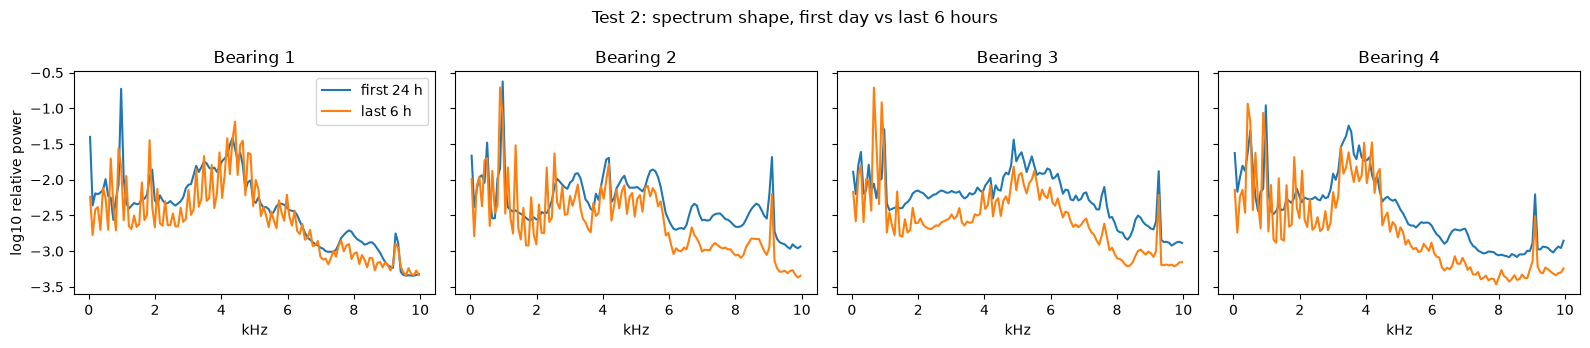

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
freq = (EDGES[:-1] + EDGES[1:]) / 2 / 1000
first_day = t2 < t2[0] + pd.Timedelta(hours=24)
for b, ax in enumerate(axes):
    ax.plot(freq, S2[first_day, b].mean(0), label="first 24 h")
    ax.plot(freq, S2[-36:, b].mean(0), label="last 6 h")
    ax.set_title(f"Bearing {b+1}"); ax.set_xlabel("kHz")
axes[0].set_ylabel("log10 relative power"); axes[0].legend()
plt.suptitle("Test 2: spectrum shape, first day vs last 6 hours"); plt.tight_layout()
plt.savefig("figures/fig1_test2_spectrum_shape.png", dpi=150); plt.show()

## 2b. Check before the VAE: how far does each bearing's shape move from its own first day?

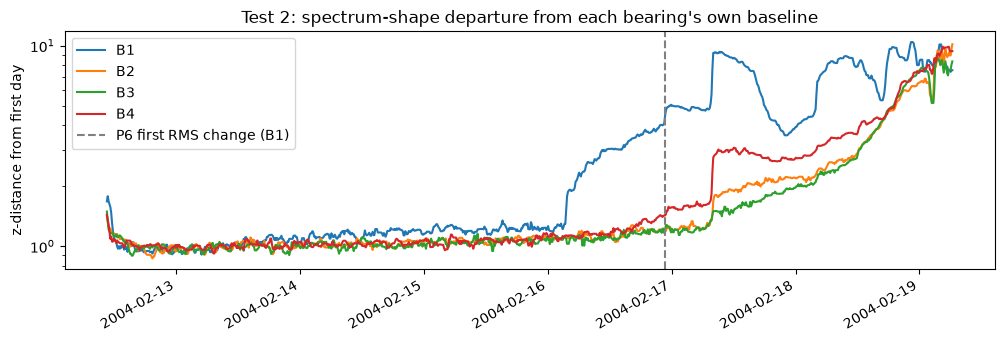

first time above 3:
 B1   2004-02-16 10:32:39
B2   2004-02-18 12:12:39
B3   2004-02-18 12:22:39
B4   2004-02-17 09:02:39
dtype: datetime64[us]


In [42]:
mu_b = S2[first_day].mean(0); sd_b = S2[first_day].std(0) + 1e-6          # per bearing, per band
dist = np.sqrt((((S2 - mu_b) / sd_b) ** 2).mean(axis=2))                  # (snapshots, 4)
d = pd.DataFrame(dist, index=t2, columns=[f"B{b}" for b in range(1, 5)]).rolling(6, min_periods=1).median()

ax = d.plot(figsize=(12, 3.5), logy=True)
ax.axvline(pd.Timestamp("2004-02-16 22:42:39"), ls="--", c="grey", label="P6 first RMS change (B1)")
ax.set_ylabel("z-distance from first day"); ax.legend()
ax.set_title("Test 2: spectrum-shape departure from each bearing's own baseline")
plt.savefig("figures/fig2_test2_shape_departure.png", dpi=150); plt.show()
print("first time above 3:\n", (d > 3).idxmax().where((d > 3).any()))

## 3. Detector: P5's VAE, trained on each run's own first healthy day

In [43]:
import torch, torch.nn as nn

class SpecVAE(nn.Module):
    """1D-convolutional VAE for 128-bin log power spectra."""
    def __init__(self, latent=8):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv1d(1, 16, 5, stride=2, padding=2), nn.LeakyReLU(0.2),   # 128 -> 64
            nn.Conv1d(16, 32, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 64 -> 32
            nn.Conv1d(32, 64, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 32 -> 16
            nn.Flatten())
        self.mu, self.logvar = nn.Linear(64 * 16, latent), nn.Linear(64 * 16, latent)
        self.fc = nn.Linear(latent, 64 * 16)
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 16 -> 32
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 32 -> 64
            nn.ConvTranspose1d(16, 1, 4, stride=2, padding=1))                      # 64 -> 128

    def encode(self, x):
        h = self.enc(x); return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.dec(self.fc(z).view(-1, 64, 16))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # reparameterisation trick
        return self.decode(z), mu, logvar

def vae_loss(x, xr, mu, logvar, beta=1.0):
    """Negative ELBO per sample: Gaussian reconstruction (sum of squared errors) + beta * KL."""
    rec = ((x - xr) ** 2).sum(dim=(1, 2)).mean()
    kl = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)).mean()
    return rec + beta * kl, rec, kl

In [44]:
def score(model, x):
    """P5's anomaly score: decode from mu (deterministic), sum of squared errors over 128 bins."""
    model.eval()
    with torch.no_grad():
        h = model.enc(x); mu = model.mu(h)
        rec = model.dec(model.fc(mu).view(-1, 64, 16))
        return ((rec - x) ** 2).sum(dim=(1, 2)).numpy()

def fit_detector(S, t, name, train_h=18, val_h=6, epochs=60, q=0.99):
    out = Path(f"data/derived/detector_{name}.npz")
    tr = t < t[0] + pd.Timedelta(hours=train_h)
    va = (t >= t[0] + pd.Timedelta(hours=train_h)) & (t < t[0] + pd.Timedelta(hours=train_h + val_h))
    if out.exists():
        d = np.load(out); return d["scores"], d["thr"], tr, va
    mean, std = S[tr].reshape(-1, 128).mean(0), S[tr].reshape(-1, 128).std(0) + 1e-6
    Z = ((S - mean) / std).astype("float32")
    torch.manual_seed(0)
    model = SpecVAE(latent=8); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    Xtr = torch.tensor(Z[tr].reshape(-1, 1, 128))
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xtr)).split(128):
            xb = Xtr[idx]
            rec, mu, lv = model(xb)
            loss, _, _ = vae_loss(xb, rec, mu, lv)   # vae_loss(x, xr, mu, logvar) returns (total, rec, kl)
            opt.zero_grad(); loss.backward(); opt.step()
    scores = score(model, torch.tensor(Z.reshape(-1, 1, 128))).reshape(len(S), 4)
    thr = np.array([np.quantile(scores[va, b], q) for b in range(4)])
    torch.save(model.state_dict(), f"data/derived/vae_{name}.pt")
    np.savez(out, scores=scores, thr=thr)
    return scores, thr, tr, va

sc2, thr2, tr2, va2 = fit_detector(S2, t2, "test2")
print("train / val snapshots:", tr2.sum(), va2.sum(), "| thresholds per bearing:", thr2.round(1))

train / val snapshots: 108 36 | thresholds per bearing: [22.1 23.1 23.2 24.2]


## 4. Detector output on test 2: VAE vs simple distance, with the same persistence rule

VAE median score  train: [16.1 16.1 16.1 14.7] | val: [16.  16.2 16.8 13.5]


,detector,bearing,first_alarm,alarm_episodes,val_flag_rate
0,VAE,1,2004-02-13 20:12:39,19,0.028
1,VAE,2,2004-02-16 15:52:39,6,0.028
2,VAE,3,2004-02-16 14:02:39,8,0.028
3,VAE,4,2004-02-16 17:22:39,8,0.028
0,distance,1,2004-02-12 10:52:39,33,0.028
1,distance,2,2004-02-16 06:02:39,12,0.028
2,distance,3,2004-02-15 15:32:39,12,0.028
3,distance,4,2004-02-15 23:12:39,7,0.028


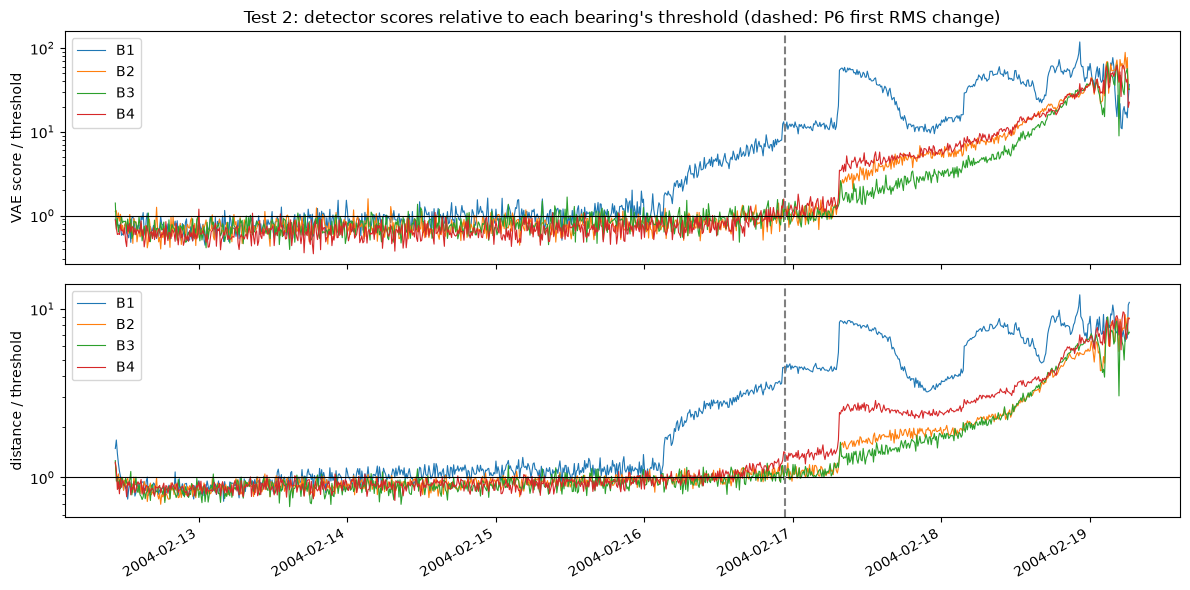

In [45]:
K = 3   # persistence: alarm only when the last K snapshots are all above threshold (fixed before seeing results)

def alarm_mask(scores, thr, k=K):
    # to_numpy(copy=True): pandas 3 returns read-only arrays from .values, and callers write into this mask
    return pd.DataFrame(scores > thr).rolling(k).sum().eq(k).to_numpy(copy=True)

def summarise(name, scores, thr, t, val):
    al = alarm_mask(scores, thr)
    first = [t[al[:, b]].min() if al[:, b].any() else pd.NaT for b in range(4)]
    episodes = (np.diff(al.astype(int), axis=0) == 1).sum(0)
    return pd.DataFrame({"detector": name, "bearing": range(1, 5), "first_alarm": first, "alarm_episodes": episodes,
                         "val_flag_rate": (scores[val] > thr).mean(0).round(3)})

# Simple baseline: z-distance from the training period (same split as the VAE)
mu_t, sd_t = S2[tr2].mean(0), S2[tr2].std(0) + 1e-6
dsc2 = np.sqrt((((S2 - mu_t) / sd_t) ** 2).mean(axis=2))
dthr2 = np.quantile(dsc2[va2], 0.99, axis=0)

print("VAE median score  train:", np.median(sc2[tr2], 0).round(1), "| val:", np.median(sc2[va2], 0).round(1))
cmp2 = pd.concat([summarise("VAE", sc2, thr2, t2, va2), summarise("distance", dsc2, dthr2, t2, va2)])
display(cmp2)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, (nm, s, th) in zip(axes, [("VAE score / threshold", sc2, thr2), ("distance / threshold", dsc2, dthr2)]):
    r = pd.DataFrame(s / th, index=t2, columns=[f"B{b}" for b in range(1, 5)])
    r.plot(ax=ax, logy=True, lw=0.8); ax.axhline(1, c="k", lw=0.8)
    ax.axvline(pd.Timestamp("2004-02-16 22:42:39"), ls="--", c="grey"); ax.set_ylabel(nm)
axes[0].set_title("Test 2: detector scores relative to each bearing's threshold (dashed: P6 first RMS change)")
plt.tight_layout(); plt.savefig("figures/fig3_test2_detectors.png", dpi=150); plt.show()

## 4b. Smooth the score before thresholding

**Why the false-alarm cut-off is midnight on Feb 17.** Test 2 has no labels for when bearings B2–B4 stop being healthy, so the cut-off is a judgement call. In both plots above (the shape departure in section 2b and the detector scores in section 4), B2–B4 stay flat until about Feb 17 07:00. The cut-off is set about seven hours earlier, at 2004-02-17 00:00. That way, any B2–B4 alarm counted as false is false by any reading of the plots, and the margin keeps the count from depending on exactly when the change began.

The count is conservative. B2–B4 alarms after midnight are not counted at all, even though some may also be false, so `false_B2_B4_before_Feb17` is a lower bound on false alarms, not a full count. B1 is left out because it is the bearing that fails.

In [46]:
## Smoothing: 1-hour rolling median of the score before thresholding (same window as the P6 router)
SMOOTH = 6   # snapshots ≈ 1 hour at 10-minute spacing

def smooth(s):
    return pd.DataFrame(s).rolling(SMOOTH, min_periods=1).median().to_numpy(copy=True)   # writable (pandas 3)

def false_episodes(scores, thr, t, healthy_until="2004-02-17 00:00"):
    """Alarm episodes that start before the cut-off on the healthy bearings (B2–B4) = false alarms."""
    al = alarm_mask(scores, thr)
    starts = np.vstack([al[:1], np.diff(al.astype(int), axis=0) == 1])
    early = t < pd.Timestamp(healthy_until)
    return int(starts[early][:, 1:].sum())

rows = []
for nm, s in [("VAE", sc2), ("distance", dsc2)]:
    for label, ss in [("raw", s), ("1-h median", smooth(s))]:
        th = np.quantile(ss[va2], 0.99, axis=0)
        r = summarise(f"{nm}, {label}", ss, th, t2, va2)
        r["false_B2_B4_before_Feb17"] = false_episodes(ss, th, t2)
        rows.append(r)
cmp2b = pd.concat(rows)
display(cmp2b.pivot(index="detector", columns="bearing", values="first_alarm"))
display(cmp2b.groupby("detector")[["alarm_episodes", "false_B2_B4_before_Feb17"]].agg({"alarm_episodes": "sum", "false_B2_B4_before_Feb17": "first"}))

bearing,1,2,3,4
detector,,,,
"VAE, 1-h median",2004-02-13 12:02:39,2004-02-12 10:52:39,2004-02-12 10:52:39,2004-02-12 10:52:39
"VAE, raw",2004-02-13 20:12:39,2004-02-16 15:52:39,2004-02-16 14:02:39,2004-02-16 17:22:39
"distance, 1-h median",2004-02-12 10:52:39,2004-02-12 10:52:39,2004-02-12 10:52:39,2004-02-12 10:52:39
"distance, raw",2004-02-12 10:52:39,2004-02-16 06:02:39,2004-02-15 15:32:39,2004-02-15 23:12:39


,alarm_episodes,false_B2_B4_before_Feb17
detector,,
"VAE, 1-h median",76,63
"VAE, raw",41,10
"distance, 1-h median",56,48
"distance, raw",64,25


## 4c. Thresholds from cross-fitting within the 24-h baseline

In [47]:
## 4c. Thresholds from cross-fitting within the 24-h baseline; alarms counted only after the baseline
BASE_H, FOLDS, Q = 24, 4, 0.99

def train_vae(Zb, epochs=60, seed=0):
    torch.manual_seed(seed)
    m = SpecVAE(latent=8); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    X = torch.tensor(Zb.reshape(-1, 1, 128))
    for _ in range(epochs):
        m.train()
        for idx in torch.randperm(len(X)).split(128):
            rec, mu, lv = m(X[idx]); loss, _, _ = vae_loss(X[idx], rec, mu, lv)
            opt.zero_grad(); loss.backward(); opt.step()
    return m

def vae_scores(m, Z):  return score(m, torch.tensor(Z.reshape(-1, 1, 128).astype("float32"))).reshape(len(Z), 4)
def dist_scores(ref, Z): return np.sqrt((((Z - ref.mean(0)) / (ref.std(0) + 1e-6)) ** 2).mean(axis=2))

def cross_fit(S, t, name, seed=0):
    tag = name if seed == 0 else f"{name}_s{seed}"             # seed 0 keeps the original file names
    out = Path(f"data/derived/cv_{tag}.npz")
    if out.exists():
        d = np.load(out); return {k: d[k] for k in d.files}
    base = np.where(t < t[0] + pd.Timedelta(hours=BASE_H))[0]
    blocks = np.array_split(base, FOLDS)                       # contiguous 6-h blocks
    oof_v, oof_d = np.zeros((len(base), 4)), np.zeros((len(base), 4))
    for blk in blocks:
        tr = np.setdiff1d(base, blk)
        mean, std = S[tr].reshape(-1, 128).mean(0), S[tr].reshape(-1, 128).std(0) + 1e-6
        m = train_vae((S[tr] - mean) / std, seed=seed)
        pos = np.searchsorted(base, blk)
        oof_v[pos] = vae_scores(m, (S[blk] - mean) / std)
        oof_d[pos] = dist_scores(S[tr], S[blk])
    mean, std = S[base].reshape(-1, 128).mean(0), S[base].reshape(-1, 128).std(0) + 1e-6
    final = train_vae((S[base] - mean) / std, seed=seed)
    torch.save(final.state_dict(), f"data/derived/vae_{tag}.pt")
    res = dict(vae=vae_scores(final, (S - mean) / std), dist=dist_scores(S[base], S),
               oof_vae=oof_v, oof_dist=oof_d, base_end=np.array([len(base)]))
    np.savez(out, **res); return res

def evaluate(name, s, oof, t, base_end, smooth_it, healthy_until="2004-02-17 00:00", failing=1):
    if smooth_it: s, oof = smooth(s), smooth(oof)
    thr = np.quantile(oof, Q, axis=0)
    al = alarm_mask(s, thr); al[:base_end] = False                # nothing counts inside the baseline
    starts = np.vstack([al[:1], np.diff(al.astype(int), axis=0) == 1])
    run = pd.DataFrame(al).apply(lambda c: c.groupby((~c).cumsum()).cumsum())  # current episode length
    rows = []
    for b in range(4):
        long6 = run[b].values >= 36                               # episode has lasted 6 h
        rows.append({"detector": name, "bearing": b + 1,
                     "first_alarm": t[al[:, b]].min() if al[:, b].any() else pd.NaT,
                     "first_6h_alarm": t[long6].min() - pd.Timedelta(hours=6) + pd.Timedelta(minutes=10) if long6.any() else pd.NaT,
                     "episodes": int(starts[:, b].sum()),
                     "false_before_cutoff": int(starts[t < pd.Timestamp(healthy_until), b].sum()) if b != failing - 1 else None})
    return pd.DataFrame(rows)

cv2 = cross_fit(S2, t2, "test2"); be2 = int(cv2["base_end"][0])
res2 = pd.concat([evaluate(f"{d}, {'1-h median' if sm else 'raw'}", cv2[d], cv2[f"oof_{d}"], t2, be2, sm)
                  for d in ["vae", "dist"] for sm in [False, True]])
display(res2.pivot(index="detector", columns="bearing", values="first_6h_alarm"))
display(res2.groupby("detector")[["episodes", "false_before_cutoff"]].sum())

bearing,1,2,3,4
detector,,,,
"dist, 1-h median",2004-02-16 04:12:39,2004-02-17 08:12:39,2004-02-17 10:12:39,2004-02-16 23:12:39
"dist, raw",2004-02-16 05:02:39,2004-02-17 07:52:39,2004-02-17 12:12:39,2004-02-16 22:22:39
"vae, 1-h median",2004-02-16 03:12:39,2004-02-17 07:42:39,2004-02-17 07:32:39,2004-02-16 17:32:39
"vae, raw",2004-02-16 03:32:39,2004-02-17 07:32:39,2004-02-17 07:22:39,2004-02-17 03:52:39


,episodes,false_before_cutoff
detector,,
"dist, 1-h median",5,1.0
"dist, raw",11,4.0
"vae, 1-h median",11,2.0
"vae, raw",12,3.0


## 4d. Seed check: does the VAE result depend on the random seed?

In [48]:
## 4d. Seed check (test 2 only): is the VAE result stable?
seed_rows = []
for sd in [0, 1, 2]:
    cv = cross_fit(S2, t2, "test2", seed=sd)
    r = evaluate(f"vae raw, seed {sd}", cv["vae"], cv["oof_vae"], t2, be2, False)
    seed_rows.append(r)
seeds2 = pd.concat(seed_rows)
display(seeds2.pivot(index="detector", columns="bearing", values="first_6h_alarm"))
display(seeds2.groupby("detector")[["episodes", "false_before_cutoff"]].sum())

bearing,1,2,3,4
detector,,,,
"vae raw, seed 0",2004-02-16 03:32:39,2004-02-17 07:32:39,2004-02-17 07:22:39,2004-02-17 03:52:39
"vae raw, seed 1",2004-02-16 03:32:39,2004-02-17 07:42:39,2004-02-17 07:52:39,2004-02-17 02:32:39
"vae raw, seed 2",2004-02-16 03:32:39,2004-02-17 07:32:39,2004-02-17 12:12:39,2004-02-17 03:52:39


,episodes,false_before_cutoff
detector,,
"vae raw, seed 0",12,3.0
"vae raw, seed 1",10,3.0
"vae raw, seed 2",12,2.0


### Design log: detector choice, fixed before test 3

Everything here was decided on test 2 alone. Test 3 hasn't been scored yet, and none of this changes once it is.

**Primary detector: the VAE on its raw score.** The threshold is the 99th percentile of the cross-fitted baseline scores, and an alarm needs 3 snapshots in a row above it. I picked it for three reasons. It's P5's method, unchanged, so nothing about it was adjusted to suit test 2. It also leaves the widest gap between the failing bearing and the healthy ones. B1's sustained alarm starts at 03:32 on Feb 16, and the first healthy bearing doesn't follow until about 24 hours later; the other variants manage 14 to 19 hours. And it has the fewest moving parts, with no smoothing window to choose. It isn't free, though: it raises 3 false alarms before the Feb 17 cut-off, where the distance baseline raises 1.

**Baseline detector: distance with a 1-hour median.** This is the simple alternative. If the VAE can't beat it on held-out data, the VAE hasn't earned its place.

**Fixed from now on:** a 24-hour baseline, 4 folds, q = 0.99, K = 3, and the 6-hour rule for a "sustained" alarm. None of these will change after test 3.

**Seed check.** Retraining with seeds 0, 1 and 2 doesn't move B1 at all, and the VAE ranks first with every seed. The healthy bearings do shift, though: B3 by almost 5 hours. So I'll report the VAE's test 3 alarm times as the range across the three seeds, not as a single time.

## 5. Test 3 (seen in P6, not used for any design choice here)

**Why the test 3 cut-off is midnight on Apr 16.** Test 3 has two possible end points. The dataset's readme says the run ended at 19:01 on Apr 4 with an outer-race failure on B3, but the files keep going until Apr 18, another 1,876 snapshots. In P6, the first real change in test 3 shows up at 22:02 on Apr 16, on B3, twelve days after the readme's end date.

So I've put the cut-off about 22 hours earlier, at 2004-04-16 00:00. It's the same idea as test 2: any alarm on B1, B2 or B4 before midnight on Apr 16 is false however you read the data, and the margin means the count doesn't depend on exactly when the change began. One difference is worth noting. For test 2, I set the cut-off from the shape plots in this notebook. For test 3, I took it straight from P6's RMS result, so nothing about test 3's spectra played a part in choosing it.

As before, `false_before_cutoff` is a lower bound. Alarms on the healthy bearings after the cut-off aren't counted, and B3 is left out because it's the bearing that fails.

**The question that matters most** is whether the shape detector catches B3 before Apr 4. P6's RMS router didn't. A sustained B3 alarm before 19:01 on Apr 4 would be something the spectrum shape picks up and loudness misses. It only counts as a catch, though, if B1, B2 and B4 stay quiet over the same stretch. Otherwise the B3 alarm can't be told apart from the false ones.

In [49]:
## 5. Test 3 (seen in P6, not used for any design choice here): same settings, nothing changed
cv3 = cross_fit(S3, t3, "test3"); be3 = int(cv3["base_end"][0])
CUT3 = "2004-04-16 00:00"   # P6's first real test-3 change was Apr 16 22:02 (B3); cut-off ~22 h earlier
res3 = pd.concat([evaluate(n, cv3[d], cv3[f"oof_{d}"], t3, be3, sm, healthy_until=CUT3, failing=3)
                  for n, d, sm in [("vae, raw (primary)", "vae", False), ("dist, 1-h median (baseline)", "dist", True)]])
display(res3.pivot(index="detector", columns="bearing", values="first_6h_alarm"))
display(res3.groupby("detector")[["episodes", "false_before_cutoff"]].sum())
README_END3 = pd.Timestamp("2004-04-04 19:01:57")
# print("B3 sustained alarm before Readme end?", (res3[res3.bearing == 3].first_6h_alarm < README_END3).to_dict())
print(res3[res3.bearing == 3].set_index("detector").first_6h_alarm.lt(README_END3).to_dict())

bearing,1,2,3,4
detector,,,,
"dist, 1-h median (baseline)",2004-03-18 01:55:20,2004-03-07 01:32:46,2004-04-04 21:11:57,2004-03-07 12:52:46
"vae, raw (primary)",2004-03-07 00:12:46,2004-03-07 10:02:46,2004-03-21 11:31:57,2004-03-13 16:42:46


,episodes,false_before_cutoff
detector,,
"dist, 1-h median (baseline)",123,73.0
"vae, raw (primary)",351,162.0


{'vae, raw (primary)': True, 'dist, 1-h median (baseline)': False}


## 5b. Diagnosis

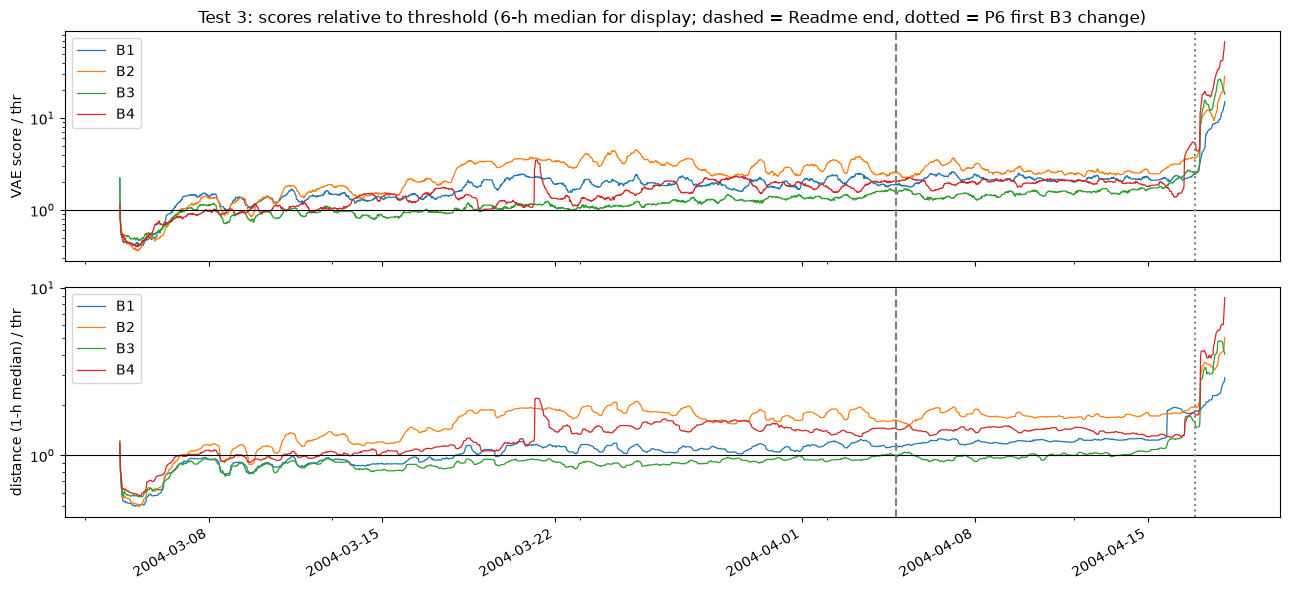

Share of snapshots above threshold, per day (VAE):


,B1,B2,B3,B4
2004-03-04,0.01,0.01,0.01,0.01
2004-03-07,0.99,0.95,0.69,0.26
2004-03-10,0.95,0.93,0.27,0.53
2004-03-13,0.98,1.00,0.28,0.76
2004-03-16,1.00,1.00,0.42,0.98
2004-03-19,1.00,1.00,0.57,0.84
2004-03-22,1.00,1.00,0.60,0.90
2004-03-25,1.00,1.00,0.83,1.00
2004-03-28,1.00,1.00,0.98,1.00
2004-03-31,1.00,1.00,0.98,1.00


Correlation of log VAE scores between bearings (after baseline):


,B1,B2,B3,B4
B1,1.00,0.87,0.80,0.78
B2,0.87,1.00,0.71,0.72
B3,0.80,0.71,1.00,0.87
B4,0.78,0.72,0.87,1.00


In [50]:
## 5b. Diagnosis: what do the test 3 scores look like over time?
thr_v3 = np.quantile(cv3["oof_vae"], Q, axis=0)
thr_d3 = np.quantile(smooth(cv3["oof_dist"]), Q, axis=0)
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, (nm, s, th) in zip(axes, [("VAE score / thr", cv3["vae"], thr_v3), ("distance (1-h median) / thr", smooth(cv3["dist"]), thr_d3)]):
    pd.DataFrame(s / th, index=t3, columns=[f"B{b}" for b in range(1, 5)]).rolling(36, min_periods=1).median().plot(ax=ax, logy=True, lw=0.9)
    ax.axhline(1, c="k", lw=0.8); ax.set_ylabel(nm)
    ax.axvline(README_END3, ls="--", c="grey"); ax.axvline(pd.Timestamp("2004-04-16 22:02"), ls=":", c="grey")
axes[0].set_title("Test 3: scores relative to threshold (6-h median for display; dashed = Readme end, dotted = P6 first B3 change)")
plt.tight_layout(); plt.savefig("figures/fig4_test3_scores.png", dpi=150); plt.show()

# How similar is the drift across bearings? (a common rig-wide drift vs. separate per-bearing changes)
daily = pd.DataFrame(cv3["vae"] > thr_v3, index=t3).resample("D").mean()
daily.columns = [f"B{b}" for b in range(1, 5)]
print("Share of snapshots above threshold, per day (VAE):"); display(daily.iloc[::3].round(2))
print("Correlation of log VAE scores between bearings (after baseline):")
display(pd.DataFrame(np.log(cv3["vae"][be3:]), columns=daily.columns).corr().round(2))

### Design log addendum: after test 3

**What the fixed design did on test 3.** I ran it exactly as logged before test 3, with nothing changed, and it didn't work. The VAE does raise a sustained B3 alarm before the readme's end date, at 11:31 on Mar 21. But by then every healthy bearing has already alarmed: B1 at 00:12 on Mar 7, B2 at 10:02 on Mar 7 and B4 at 16:42 on Mar 13. There are 162 false alarm episodes before the Apr 16 cut-off. So that B3 alarm can't be told apart from the noise, and by the test I set in advance it isn't a catch. The distance baseline is quieter, with 73 false episodes, but its B3 alarm comes at 21:11 on Apr 4, about two hours after the readme's end, and its healthy bearings alarm from Mar 7 too. Neither detector does what P6's RMS router couldn't. These are seed 0 results only. I said I'd report test 3 as a range across seeds 0, 1 and 2, and I haven't done that yet.

**Why I added Variant 4.** The diagnosis in 5b shows why the alarms came so early. The scores aren't rising on one bearing at a time; they rise on all four together. By Mar 7, three days in, B1 and B2 are above threshold on nearly every snapshot. After the baseline, the log VAE scores of the four bearings are correlated at 0.71 to 0.87. That looks like a drift shared across the whole rig, not separate changes in separate bearings, and a detector that compares each bearing only with its own first day can't tell the two apart. Variant 4 compares each bearing's score with the median of the other three at the same moment, so a drift they all share should cancel out and leave only what is specific to one bearing.

**Test 3 is no longer a clean test.** Variant 4 exists because I saw how the fixed design failed on test 3, so test 3 can't tell me whether Variant 4 works. It's now a test I've seen and adjusted for, just like test 2. Test 1 is the only real held-out check left, and I'll write down what I expect from it before looking at any of its signals.

**Risks for test 1.**

- **The drift may or may not be there.** Test 2 showed no shared drift, and test 3 was dominated by it. With one run of each, I can't say which one test 1 will look like. If it drifts, the fixed design will flood with false alarms, as it did on test 3.
- **Variant 4 has only test 2 behind it.** On test 2 the VAE version looks clean: B1 alarms at 04:32 on Feb 16, an hour later than the fixed design, and none of the healthy bearings alarm. But on test 3, the run it was built for, it doesn't solve the problem. It raises 214 false episodes before the cut-off, more than the fixed design, and never alarms on B3. Test 1 will be its first fair test, and it may fail.
- **Two failing bearings.** According to the readme, test 1 ends with defects on two bearings, B3 (inner race) and B4 (roller element). Variant 4 assumes that most bearings are healthy at any moment. A median of three tolerates one bearing that is off, so B3 and B4 failing together should still show, but only if B1 and B2 stay quiet.
- **Snapshot counts are not hours.** The persistence rule (K = 3), the 6-hour sustained rule (36 snapshots) and the 1-hour median (6 snapshots) all count snapshots and assume 10-minute spacing. Test 1 has 117 shorter gaps after the baseline, so in those stretches "6 hours" is really less.
- **Seed spread.** On test 2, healthy-bearing alarm times moved by up to 5 hours between seeds. Test 1 results will be reported as a range across seeds 0, 1 and 2.

## 5c. Variant 4 (decided after test 3)

In [51]:
## 5c. Variant 4 (decided after test 3): each bearing's score relative to the other bearings at the same moment
def relative(s, thr):
    L = np.log(s / thr)
    others = np.stack([np.median(np.delete(L, b, axis=1), axis=1) for b in range(4)], axis=1)
    return np.exp(L - others)        # > 1: this bearing is further from its baseline than the typical other bearing

def evaluate_rel(name, s, oof, t, base_end, smooth_it, healthy_until, failing):
    if smooth_it: s, oof = smooth(s), smooth(oof)
    thr = np.quantile(oof, Q, axis=0)
    return evaluate(name, relative(s, thr), relative(oof, thr), t, base_end, False, healthy_until, failing)

runs = [("vae raw", "vae", False), ("dist 1-h median", "dist", True)]
rel = pd.concat(
    [evaluate_rel(f"test 2 | {n} | relative", cv2[d], cv2[f"oof_{d}"], t2, be2, sm, "2004-02-17 00:00", 1) for n, d, sm in runs] +
    [evaluate_rel(f"test 3 | {n} | relative", cv3[d], cv3[f"oof_{d}"], t3, be3, sm, CUT3, 3) for n, d, sm in runs])
display(rel.pivot(index="detector", columns="bearing", values="first_6h_alarm"))
display(rel.groupby("detector")[["episodes", "false_before_cutoff"]].sum())

bearing,1,2,3,4
detector,,,,
test 2 | dist 1-h median | relative,2004-02-16 03:52:39,NaT,NaT,2004-02-16 23:22:39
test 2 | vae raw | relative,2004-02-16 04:32:39,NaT,NaT,NaT
test 3 | dist 1-h median | relative,2004-04-15 16:02:55,2004-03-07 09:42:46,NaT,2004-03-21 01:51:57
test 3 | vae raw | relative,NaT,2004-03-17 19:15:20,NaT,2004-04-17 12:42:55


,episodes,false_before_cutoff
detector,,
test 2 | dist 1-h median | relative,11,4.0
test 2 | vae raw | relative,7,0.0
test 3 | dist 1-h median | relative,124,111.0
test 3 | vae raw | relative,234,214.0


## 6. Router v3

In [52]:
## 6. Router v3: wake the agent when a bearing's debounced (absolute, relative) alarm state changes
HOLD, RECHECK_H, PERIODIC_H = 6, 6, 12

def debounce(m, n=HOLD):
    """A state change counts only after the new value has held for n snapshots."""
    out = m.copy()
    for b in range(m.shape[1]):
        cur = m[0, b]
        for i in range(m.shape[0]):
            if i >= n - 1 and (m[i - n + 1:i + 1, b] != cur).all(): cur = m[i, b]
            out[i, b] = cur
    return out

def detector_states(cv, base_end):
    thr = np.quantile(cv["oof_vae"], Q, axis=0)
    rel_s, rel_oof = relative(cv["vae"], thr), relative(cv["oof_vae"], thr)
    a = alarm_mask(cv["vae"], thr); r = alarm_mask(rel_s, np.quantile(rel_oof, Q, axis=0))
    a[:base_end] = r[:base_end] = False
    return debounce(a), debounce(r), cv["vae"] / thr, rel_s

def router_v3(a, r, t, base_end):
    log, last = [], {b: t[base_end - 1] for b in range(4)}
    for i in range(base_end, len(t)):
        for b in range(4):
            state, prev = (a[i, b], r[i, b]), (a[i - 1, b], r[i - 1, b])
            since = t[i] - last[b]
            if state != prev:                                        why = f"change: abs={int(state[0])} rel={int(state[1])}"
            elif any(state) and since >= pd.Timedelta(hours=RECHECK_H): why = "recheck_while_alarm"
            elif since >= pd.Timedelta(hours=PERIODIC_H):              why = "periodic"
            else: continue
            log.append({"idx": i, "time": t[i], "bearing": b + 1, "why": why}); last[b] = t[i]
    return pd.DataFrame(log)

for name, cv, t, be in [("test 2", cv2, t2, be2), ("test 3", cv3, t3, be3)]:
    a, r, _, _ = detector_states(cv, be)
    w = router_v3(a, r, t, be)
    print(f"{name}: {len(w)} wake-ups | by bearing {w.groupby('bearing').size().to_dict()} | "
          f"by reason {w.why.str.split(':').str[0].value_counts().to_dict()} | est. {len(w) * 11 / 60:.0f} min at ~11 s/event")

test 2: 66 wake-ups | by bearing {1: 20, 2: 15, 3: 15, 4: 16} | by reason {'recheck_while_alarm': 32, 'periodic': 26, 'change': 8} | est. 12 min at ~11 s/event
test 3: 716 wake-ups | by bearing {1: 180, 2: 196, 3: 164, 4: 176} | by reason {'recheck_while_alarm': 525, 'change': 148, 'periodic': 43} | est. 131 min at ~11 s/event
